In [102]:
# Import all the required variables here
from typing import Annotated
from pydantic import BaseModel, Field
import operator
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, Send
from langchain_community.retrievers import WikipediaRetriever
from langchain_openai import ChatOpenAI
from tavily import TavilyClient
from dotenv import load_dotenv
import os
import requests

# Load environment variables
load_dotenv()

# Initialize LLM and Wikipedia retriever
llm = ChatOpenAI(model_name="gpt-4o", temperature=0.0)
wiki = WikipediaRetriever()

In [103]:
# Define all the states required for our Supervisor Worker example

def keep_non_empty(a: str, b: str) -> str:
    """Reducer that keeps the non-empty string value."""
    return a if a else b


class ResearchState(BaseModel):
    """Main state for the research workflow with reducers for parallel execution."""
    
    query: Annotated[str, keep_non_empty] = Field(
        default="",
        description="The user's research question (cleaned and prepared)"
    )
    
    candidate_urls: Annotated[list[str], operator.add] = Field(
        default_factory=list,
        description="URLs from Wikipedia and Tavily searches (merged via operator.add)"
    )
    
    page_texts: Annotated[list[str], operator.add] = Field(
        default_factory=list,
        description="Fetched content from URLs (merged via operator.add)"
    )
    
    draft_summary: Annotated[str, keep_non_empty] = Field(
        default="",
        description="Draft summary from initial processing"
    )
    
    final_report: Annotated[str, keep_non_empty] = Field(
        default="",
        description="Final research report"
    )
    
    errors: Annotated[list[str], operator.add] = Field(
        default_factory=list,
        description="Error messages from workflow (merged via operator.add)"
    )
    
    use_cache: bool = Field(
        default=False,
        description="Flag to indicate if cached data should be used"
    )
    
    fetching_initiated: bool = Field(
        default=False,
        description="Flag to track if fetch workers have been dispatched"
    )


class FetchState(BaseModel):
    """State for individual URL fetch workers (used with Send)."""
    
    url: str = Field(
        description="Single URL to fetch"
    )
    
    content: str = Field(
        default="",
        description="Fetched content from the URL"
    )
    
    error: str = Field(
        default="",
        description="Error message if fetch fails"
    )

In [104]:
# ============================================================================
# WORKER NODES
# ============================================================================

def prepare_query(state: ResearchState) -> dict:
    """Worker node: Cleans and prepares the query."""
    query = state.query if isinstance(state, ResearchState) else state.get('query', '')
    cleaned = query.strip().lower() if query else ""
    return {"query": cleaned}


def search_wikipedia(state: ResearchState) -> dict:
    """Worker node: Searches Wikipedia for relevant content."""
    query = state.query if isinstance(state, ResearchState) else state.get('query', '')    
    if not query or query.strip() == "":
        return {"candidate_urls": [], "page_texts": []}
    
    urls = []
    texts = []
    
    try:
        docs = wiki.invoke(query)        
        for doc in docs[:3]:  # Limit to 3 documents
            url = doc.metadata.get("url", "")
            if not url or not url.startswith("http"):
                title = doc.metadata.get("title", "").replace(" ", "_")
                url = f"https://en.wikipedia.org/wiki/{title}"
            urls.append(url)
            texts.append(doc.page_content[:500])  # First 500 chars
                
    except Exception as e:
        print(f"  - Error: {str(e)}")
        return {"candidate_urls": [], "page_texts": [], "errors": [f"Wikipedia error: {str(e)}"]}
    
    return {"candidate_urls": urls, "page_texts": texts}


def search_web(state: ResearchState) -> dict:
    """Worker node: Searches the web using Tavily."""
    query = state.query if isinstance(state, ResearchState) else state.get('query', '')
        
    if not query or query.strip() == "":
        return {"candidate_urls": []}
    
    web_urls = []
    errors = []
    
    try:
        tavily_api_key = os.getenv("TAVILY_API_KEY")
        if not tavily_api_key:
            raise ValueError("TAVILY_API_KEY not set")
        
        tavily_client = TavilyClient(api_key=tavily_api_key)
        response = tavily_client.search(query=query, max_results=3)
        web_urls = [result["url"] for result in response.get("results", [])]
        
    except Exception as e:
        print(f"  - Error: {str(e)}")
        errors.append(f"Tavily error: {str(e)}")
    
    return {"candidate_urls": web_urls, "errors": errors}


def fetch_url(state: FetchState) -> dict:
    """
    Worker node: Fetches content from a single URL (used with Send for parallel execution).
    """
    url = state.url if isinstance(state, FetchState) else state.get('url', '')
    
    try:
        # Add headers to avoid Wikipedia's 403 Forbidden error
        headers = {
            'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'
        }
        
        response = requests.get(url, timeout=10, headers=headers)
        response.raise_for_status()
        content = response.text[:5000]
        return {"page_texts": [content]}
    except Exception as e:
        error_msg = f"Error fetching {url}: {str(e)}"
        print(f"  - Failed: {str(e)[:80]}")
        return {"errors": [error_msg]}


def merge_results(state: ResearchState) -> dict:
    """Worker node: Merges results from parallel searches."""
    urls = state.candidate_urls if isinstance(state, ResearchState) else state.get('candidate_urls', [])
    unique_urls = list(set(urls))
    
    return {"candidate_urls": unique_urls}


def summarize_results(state: ResearchState) -> dict:
    """Worker node: Summarizes the gathered content."""
    page_texts = state.page_texts if isinstance(state, ResearchState) else state.get('page_texts', [])
    combined = "\n\n".join(page_texts)
    
    if not combined or len(combined.strip()) < 10:
        return {"final_report": "No content found to summarize."}
    
    try:
        prompt = f"Summarize the following research content concisely:\n\n{combined[:2000]}"
        response = llm.invoke(prompt)
        summary = response.content
        return {"final_report": summary}
    except Exception as e:
        return {"final_report": f"Error generating summary: {str(e)}"}


def error_handler(state: ResearchState) -> dict:
    """Worker node: Handles errors."""
    errors = state.errors if isinstance(state, ResearchState) else state.get('errors', [])
    
    for error in errors:
        print(f"  - {error}")
    
    return {"final_report": f"Workflow completed with {len(errors)} error(s). Check errors list."}


# ============================================================================
# SUPERVISOR NODE - Coordinates workflow using Command
# ============================================================================

def supervisor(state: ResearchState):
    """
    Supervisor node: Coordinates the entire workflow using Command for runtime control.
    This is the central coordinator - all work flows through this node.
    """
    from langgraph.types import Command
    
    query = state.query if isinstance(state, ResearchState) else state.get('query', '')
    errors = state.errors if isinstance(state, ResearchState) else state.get('errors', [])
    urls = state.candidate_urls if isinstance(state, ResearchState) else state.get('candidate_urls', [])
    page_texts = state.page_texts if isinstance(state, ResearchState) else state.get('page_texts', [])
    fetching_initiated = state.fetching_initiated if isinstance(state, ResearchState) else state.get('fetching_initiated', False)
    
    # Step 1: If we have sufficient page texts (from Wikipedia + fetched URLs), summarize
    # Prioritize this over error handling - if we have content, use it even if some URLs failed
    if fetching_initiated and page_texts and len(page_texts) >= 3:
        if errors:
            print(f"[SUPERVISOR] {len(page_texts)} page texts collected (with {len(errors)} errors) - routing to summarize_results")
        else:
            print(f"[SUPERVISOR] {len(page_texts)} page texts collected after fetching - routing to summarize_results")
        return Command(goto="summarize_results")
    
    # Step 2: If there are errors AND no usable content, handle them (error_handler will end workflow)
    if errors and (not page_texts or len(page_texts) < 3):
        print("[SUPERVISOR] Errors detected with insufficient content - routing to error_handler")
        return Command(goto="error_handler")
    
    # Step 3: If we have URLs but haven't dispatched fetchers yet, dispatch them
    # (Do this BEFORE summarizing to ensure we fetch all URLs, even if Wikipedia gave us initial texts)
    if urls and len(urls) > 0 and not fetching_initiated:
        print(f"[SUPERVISOR] {len(urls)} URLs found - routing to dispatcher")
        return Command(goto="dispatcher")
    
    # Step 4: If we're currently fetching but no results yet, wait for first result
    # This will be called by first fetch_url worker, then we check if we have enough
    if fetching_initiated:
        # Already fetching, and we've been called by a worker
        # Just continue - we'll route to summarization when we have enough texts
        print(f"[SUPERVISOR] Fetch in progress, {len(page_texts)} texts so far...")
        return {}  # Wait for more or proceed if we have enough
    
    # Step 5: If query not prepared yet, prepare it
    if not query or query.strip() == "":
        print("[SUPERVISOR] Preparing query")
        return Command(goto="prepare_query")
    
    # Step 6: If no URLs, run search
    print("[SUPERVISOR] No URLs found - routing to search_subgraph")
    return Command(goto="search_subgraph")


# ============================================================================
# DISPATCHER FUNCTION - Returns Send objects for conditional edge
# ============================================================================

def dispatch_fetchers(state: ResearchState):
    """
    Dispatcher function: Returns Send objects for conditional edge from dispatcher node.
    This demonstrates dynamic parallelism where the number of workers
    is determined at runtime. Each fetch_url worker will return to supervisor via edge.
    """
    from langgraph.types import Send
    
    urls = state.candidate_urls if isinstance(state, ResearchState) else state.get('candidate_urls', [])
    
    print(f"\n[DISPATCH_FETCHERS] Spawning {min(len(urls), 5)} fetch workers")
    
    # Create a Send command for each URL
    # Each fetch_url worker will automatically return to supervisor via the fetch_url->supervisor edge
    sends = []
    for url in urls[:5]:  # Limit to 5 concurrent fetches
        sends.append(Send("fetch_url", {"url": url}))
    
    return sends

In [ ]:
from langgraph.types import Command
from langgraph.store.memory import InMemoryStore
from langgraph.types import CachePolicy
from langgraph.cache.memory import InMemoryCache

cache_store = InMemoryStore()
memory_cache = InMemoryCache()

def create_search_subgraph():
    """Creates and returns the search subgraph for parallel Wikipedia and web searches."""
    search_subgraph = StateGraph(ResearchState)

    search_subgraph.add_node("search_wikipedia", search_wikipedia, cache_policy=CachePolicy(ttl=300))
    search_subgraph.add_node("search_web", search_web, cache_policy=CachePolicy(ttl=300))
    search_subgraph.add_node("merge_results", merge_results, cache_policy=CachePolicy(ttl=300))

    # Parallel execution: both searches start from entry point
    search_subgraph.set_entry_point("search_wikipedia")
    search_subgraph.set_entry_point("search_web")

    # Both searches flow to merge
    search_subgraph.add_edge("search_wikipedia", "merge_results")
    search_subgraph.add_edge("search_web", "merge_results")

    # Merge is the exit point
    search_subgraph.set_finish_point("merge_results")
    
    return search_subgraph


search_subgraph = create_search_subgraph().compile()

main_graph = StateGraph(ResearchState)

# Add worker nodes
main_graph.add_node("prepare_query", prepare_query, cache_policy=CachePolicy(ttl=300))
main_graph.add_node("error_handler", error_handler, cache_policy=CachePolicy(ttl=300))
main_graph.add_node("summarize_results", summarize_results, cache_policy=CachePolicy(ttl=300))

# Add SUPERVISOR node (key coordinator using Command)
main_graph.add_node("supervisor", supervisor, cache_policy=CachePolicy(ttl=300))

# Add search subgraph as a node
main_graph.add_node("search_subgraph", search_subgraph)

# Add fetch_url worker (will be spawned multiple times via Send)
main_graph.add_node("fetch_url", fetch_url, cache_policy=CachePolicy(ttl=300))

# Add dispatcher node - sets fetching_initiated flag and spawns workers
main_graph.add_node("dispatcher", lambda state: {"fetching_initiated": True}, cache_policy=CachePolicy(ttl=300))

main_graph.add_edge(START, "supervisor")

# All worker nodes return back to SUPERVISOR for next decision (except terminal nodes)
main_graph.add_edge("prepare_query", "supervisor")
main_graph.add_edge("search_subgraph", "supervisor")

# Terminal nodes go directly to END
main_graph.add_edge("error_handler", END)
main_graph.add_edge("summarize_results", END)

# fetch_url workers return to supervisor to trigger summarization
main_graph.add_edge("fetch_url", "supervisor")

# Dispatcher node uses conditional edge to spawn Send workers
main_graph.add_conditional_edges(
    "dispatcher",
    dispatch_fetchers,  # Function that returns Send objects
)

Building Supervisor-Worker Graph with Runtime Control
✓ Search subgraph created (Wikipedia + Tavily -> Merge)
✓ Supervisor node added (coordinates workflow with Command)
✓ Dispatcher node added (spawns workers with Send via conditional edge)


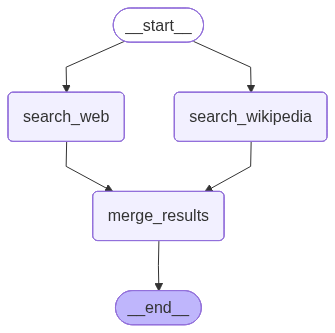

In [106]:
from IPython.display import Image, display
display(Image(search_subgraph.get_graph().draw_mermaid_png()))

In [107]:
from langgraph.checkpoint.memory import MemorySaver

app = main_graph.compile(
    checkpointer=MemorySaver(),  # State history & checkpointing
    store=cache_store,            # Key-value store for data
    cache=memory_cache            # Task-level caching (300s TTL per CachePolicy)
)

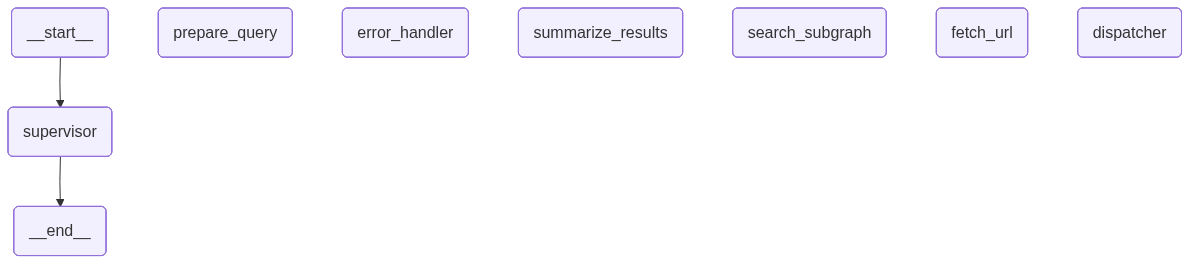

In [108]:
display(Image(app.get_graph().draw_mermaid_png()))

In [113]:
# Initialize state
initial_state = {
    "query": "What is difference between python and cobol?",
    "candidate_urls": [],
    "page_texts": [],
    "draft_summary": "",
    "final_report": "",
    "errors": [],
    "use_cache": False,
    "fetching_initiated": False
}


config = {
    "configurable": {
        "thread_id": "research_demo_5"
    },
    "recursion_limit": 50  # Increase recursion limit for safety
}

print("\n" + "="*80)
print("RUNNING RESEARCH AGENT")
print("="*80)

# Run the graph
try:
    final_state = app.invoke(initial_state, config=config)
    
    print("\n" + "="*80)
    print("SOURCES FOUND")
    print("="*80)
    if final_state['candidate_urls']:
        for i, url in enumerate(final_state['candidate_urls'][:10], 1):
            print(f"  {i}. {url}")
    
    
    print(f"\n{'='*80}")
    print("FINAL REPORT")
    print(f"{'='*80}\n")
    print(final_state['final_report'])
    
    if final_state['errors']:
        print(f"\n{'='*80}")
        print("ERRORS")
        print(f"{'='*80}")
        for error in final_state['errors']:
            print(f"  • {error}")
    
    print("\n" + "="*80)
    print("WORKFLOW COMPLETED")
    print("="*80)
    
except Exception as e:
    print(f"\n{'='*80}")
    print("ERROR DURING EXECUTION")
    print(f"{'='*80}")
    print(f"\n{str(e)}")
    import traceback
    traceback.print_exc()


RUNNING RESEARCH AGENT
[SUPERVISOR] No URLs found - routing to search_subgraph
[SUPERVISOR] 12 URLs found - routing to dispatcher

[DISPATCH_FETCHERS] Spawning 5 fetch workers
  - Failed: 403 Client Error: Forbidden for url: https://www.6sense.com/tech/programming-lan
[SUPERVISOR] 7 page texts collected (with 1 errors) - routing to summarize_results

SOURCES FOUND
  1. https://www.retrocode.de/post/cobol-vs-python-a-comparison-of-the-two-programming-languages
  2. https://stackshare.io/stackups/cobol-vs-python
  3. https://www.6sense.com/tech/programming-language/python-vs-cobol
  4. https://en.wikipedia.org/wiki/Camel_case
  5. https://en.wikipedia.org/wiki/Python_(programming_language)
  6. https://en.wikipedia.org/wiki/Mojo_(programming_language)
  7. https://stackshare.io/stackups/cobol-vs-python
  8. https://en.wikipedia.org/wiki/Camel_case
  9. https://en.wikipedia.org/wiki/Python_(programming_language)
  10. https://en.wikipedia.org/wiki/Mojo_(programming_language)

FINAL REPOR

## Inspecting State History

LangGraph provides `get_state_history()` to inspect how the state evolved during execution. This is useful for:
- Debugging workflow execution
- Understanding state transitions
- Tracking which nodes modified which state fields
- Analyzing the execution path

In [117]:
print("\n" + "="*80)
print("STATE HISTORY")
print("="*80)

state_history = list(app.get_state_history(config = {"configurable": {"thread_id": "research_demo_5"}}))
# Sort state history by step number
sorted_history = sorted(state_history, key=lambda x: x.metadata.get('step', -1))

print("="*80)
print("SORTED STATE HISTORY (by step)")
print("="*80)

for i, snapshot in enumerate(sorted_history):
    
    metadata = snapshot.metadata
    
    values = snapshot.values
    if values:
        print(f"\nState snapshot:")
        print(f"  Query: {values.get('query', 'N/A')[:50]}...")
        print(f"  URLs collected: {len(values.get('candidate_urls', []))}")
        print(f"  Texts collected: {len(values.get('page_texts', []))}")
        print(f"  Errors: {len(values.get('errors', []))}")
        
        if values.get('final_report'):
            print(f"  Final report: {values['final_report'][:80]}...")


STATE HISTORY
SORTED STATE HISTORY (by step)

State snapshot:
  Query: ...
  URLs collected: 0
  Texts collected: 0
  Errors: 0

State snapshot:
  Query: What is difference between python and cobol?...
  URLs collected: 0
  Texts collected: 0
  Errors: 0

State snapshot:
  Query: What is difference between python and cobol?...
  URLs collected: 0
  Texts collected: 0
  Errors: 0

State snapshot:
  Query: What is difference between python and cobol?...
  URLs collected: 12
  Texts collected: 3
  Errors: 0

State snapshot:
  Query: What is difference between python and cobol?...
  URLs collected: 12
  Texts collected: 3
  Errors: 0

State snapshot:
  Query: What is difference between python and cobol?...
  URLs collected: 12
  Texts collected: 3
  Errors: 0

State snapshot:
  Query: What is difference between python and cobol?...
  URLs collected: 12
  Texts collected: 7
  Errors: 1

State snapshot:
  Query: What is difference between python and cobol?...
  URLs collected: 12
  Texts co

In [ ]:
import traceback

print("\n" + "="*80)
print("RESUMING FROM CHECKPOINT 4")
print("="*80)

# Get the state at step 4 from history
step_4_state = sorted_history[4].values

print("="*80)
print("RESUMING FROM CHECKPOINT 4")
print("="*80)

print(f"\nState at step 4:")
print(f"  Query: {step_4_state['query']}")
print(f"  URLs collected: {len(step_4_state['candidate_urls'])}")
print(f"  Texts collected: {len(step_4_state['page_texts'])}")

# Resume execution from checkpoint 4
config_resume = {"configurable": {"thread_id": "research_demo_5", "checkpoint_id": sorted_history[4].config["configurable"]["checkpoint_id"]}}

print(f"\nResuming from checkpoint: {config_resume['configurable']['checkpoint_id'][:16]}...")

try:
    # Invoke from the checkpoint to continue execution
    resumed_state = app.invoke(None, config=config_resume)
    
    print(f"\nFinal Report (from resumed execution):")
    print(resumed_state['final_report'])
    
except Exception as e:
    print(f"\nError during resume: {str(e)}")
    traceback.print_exc()

RESUMING FROM CHECKPOINT 4

State at step 4:
  Query: What is difference between python and cobol?
  URLs collected: 12
  Texts collected: 3

Resuming from checkpoint: 1f0e3f32-cc72-6b...

[DISPATCH_FETCHERS] Spawning 5 fetch workers
  - Failed: 403 Client Error: Forbidden for url: https://www.6sense.com/tech/programming-lan
[SUPERVISOR] 7 page texts collected (with 1 errors) - routing to summarize_results

Final Report (from resumed execution):
The content discusses three main topics:

1. **Camel Case Writing Format**: Camel case, also known as camel caps or medial capitals, is a writing style where phrases are written without spaces or punctuation, and each word starts with a capital letter except possibly the first. Examples include YouTube, PowerPoint, and iPhone. It is commonly used for naming conventions.

2. **Python Programming Language**: Python is a high-level, general-purpose programming language known for its code readability and significant indentation. It supports multipl